# V2 — Volume incertain, coût et probabilité de terminer

Question : **combien coûte une meilleure complétion lorsque les volumes sont mal prévus ?** Le protocole est fixé localement avant l'évaluation complète, sans préenregistrement indépendant.

Les tables proviennent de `python -m execution_cost_analytics study`. Ce notebook recalcule les statistiques depuis les observations exportées et lit la confrontation historique. La CLI régénère les simulations complètes ; les sorties de référence permettent de lire ce notebook sans télécharger les données brutes.


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

from execution_cost_analytics.study import grid_invariance_check, load_protocol, summarize_study

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
protocol = load_protocol()
metadata = json.loads((ROOT / "reports/study/experiment.json").read_text(encoding="utf-8"))
summary = pd.read_csv(ROOT / "reports/study/summary.csv")
assert metadata["analysis_status"] == "pre_specified_test"
assert set(metadata["executed_seeds"]).isdisjoint(protocol["development_seeds"])
assert protocol["training"]["seed"] not in metadata["executed_seeds"]
print("Chemins indépendants test :", summary["path_id"].nunique())
print("Observations de stratégie :", len(summary))

Chemins indépendants test : 80
Observations de stratégie : 12800


## 1. Contraste principal annoncé

ADAPTIVE contre VWAP, volume à 55 %, ordre de 10 % du volume prévu, urgence finale commune, impact racine. Les autres cellules sont descriptives. Les cinq transformations d'un même chemin et ses barres ne sont pas des observations indépendantes supplémentaires.


,scenario,n_pairs,saving_bps,saving_ci_low,saving_ci_high,completion_delta_pp,completion_noninferiority_bound_pp,evidence
55,low_volume,80,0.109,-0.1268,0.3712,0.0,-16.5369,uncertain_or_no_economic_saving


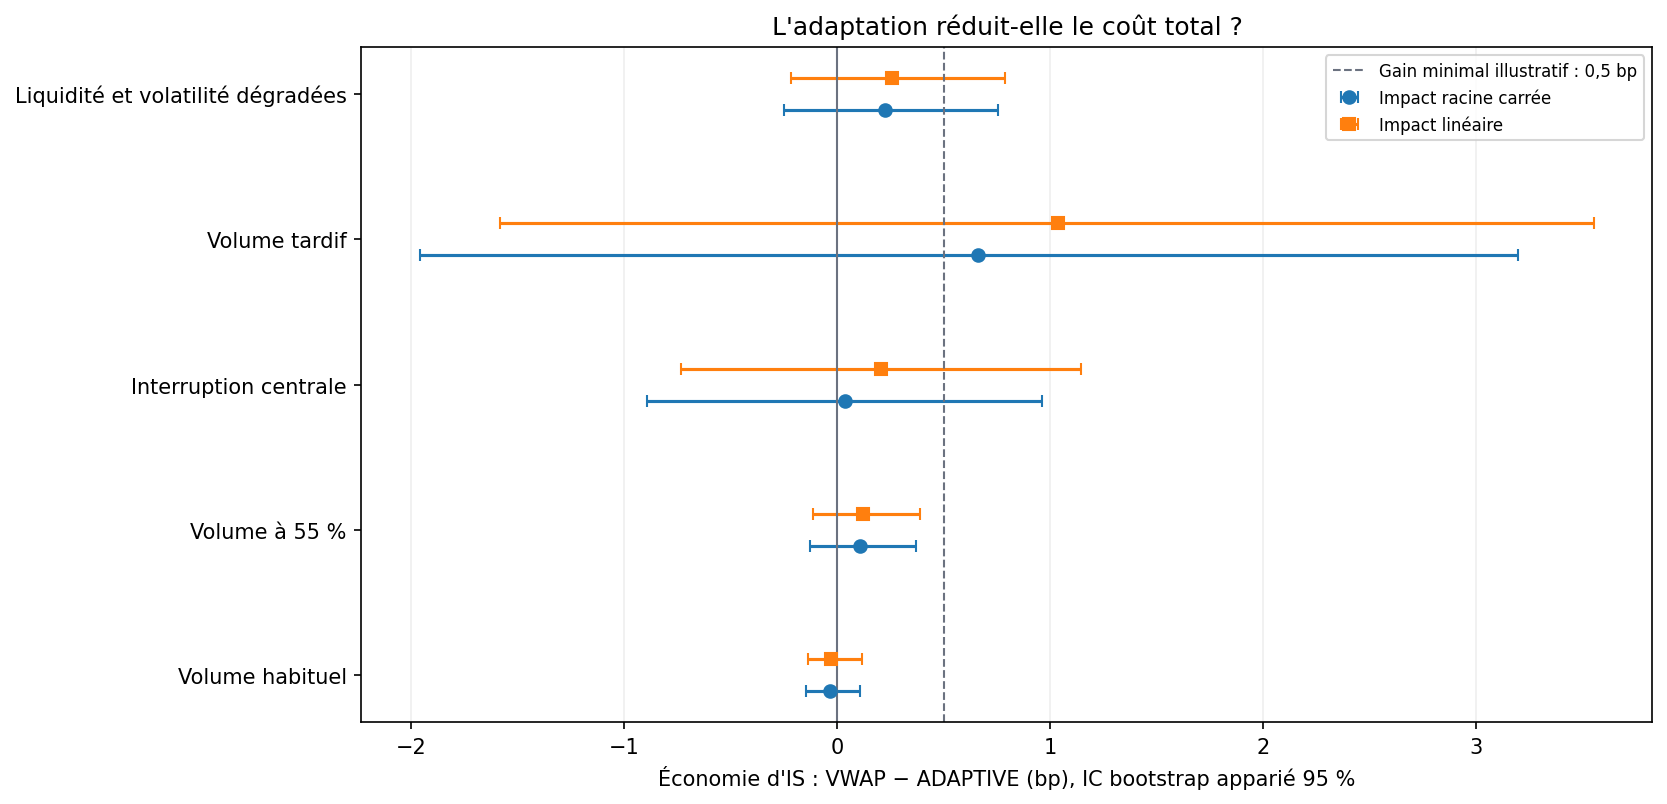

In [2]:
aggregate, comparisons = summarize_study(summary, protocol, split="test")
primary = comparisons.loc[comparisons["is_primary"]]
columns = [
    "scenario",
    "n_pairs",
    "saving_bps",
    "saving_ci_low",
    "saving_ci_high",
    "completion_delta_pp",
    "completion_noninferiority_bound_pp",
    "evidence",
]
display(primary[columns].round(4))
reference = pd.read_csv(ROOT / "reports/study/comparisons.csv")
assert np.allclose(comparisons["saving_bps"], reference["saving_bps"], atol=1e-6)
display(Image(filename=str(ROOT / "reports/study/figures/paired_savings.png")))

## 2. Coût et probabilité de terminer

Le taux moyen de remplissage et la probabilité de terminer un ordre sont distincts. L'IS inclut les mouvements de marché et l'opportunité du reliquat ; le coût explicite additionne spread, impact et frais.

Un bootstrap peut donner `[0 ; 0]` lorsque tous les indicateurs observés coïncident. La borne prudente Wilson évite d'en déduire une non-infériorité établie. Les seuils de 0,5 bp et 1 point de complétion sont des hypothèses pédagogiques, pas des normes de marché.


,deadline_mode,strategy,mean_explicit_cost_bps,mean_cost_bps,mean_fill_rate,completion_probability,completion_probability_ci_low,completion_probability_ci_high
48,soft,TWAP,4.2120,-11.9325,0.7538,0.0000,0.0000,0.0458
49,soft,VWAP,4.5195,-11.5389,0.7950,0.0000,0.0000,0.0458
50,soft,POV,2.7195,-15.4101,0.5424,0.0000,0.0000,0.0458
51,soft,ADAPTIVE,4.5693,-11.6923,0.8017,0.1000,0.0515,0.1851
52,common_deadline,TWAP,6.5272,-10.3372,0.9766,0.8250,0.7274,0.8928
53,common_deadline,VWAP,6.5243,-10.0013,0.9769,0.8250,0.7274,0.8928
54,common_deadline,POV,6.3865,-13.0379,0.9314,0.5625,0.4534,0.6659
55,common_deadline,ADAPTIVE,6.5213,-10.1103,0.9769,0.8250,0.7274,0.8928


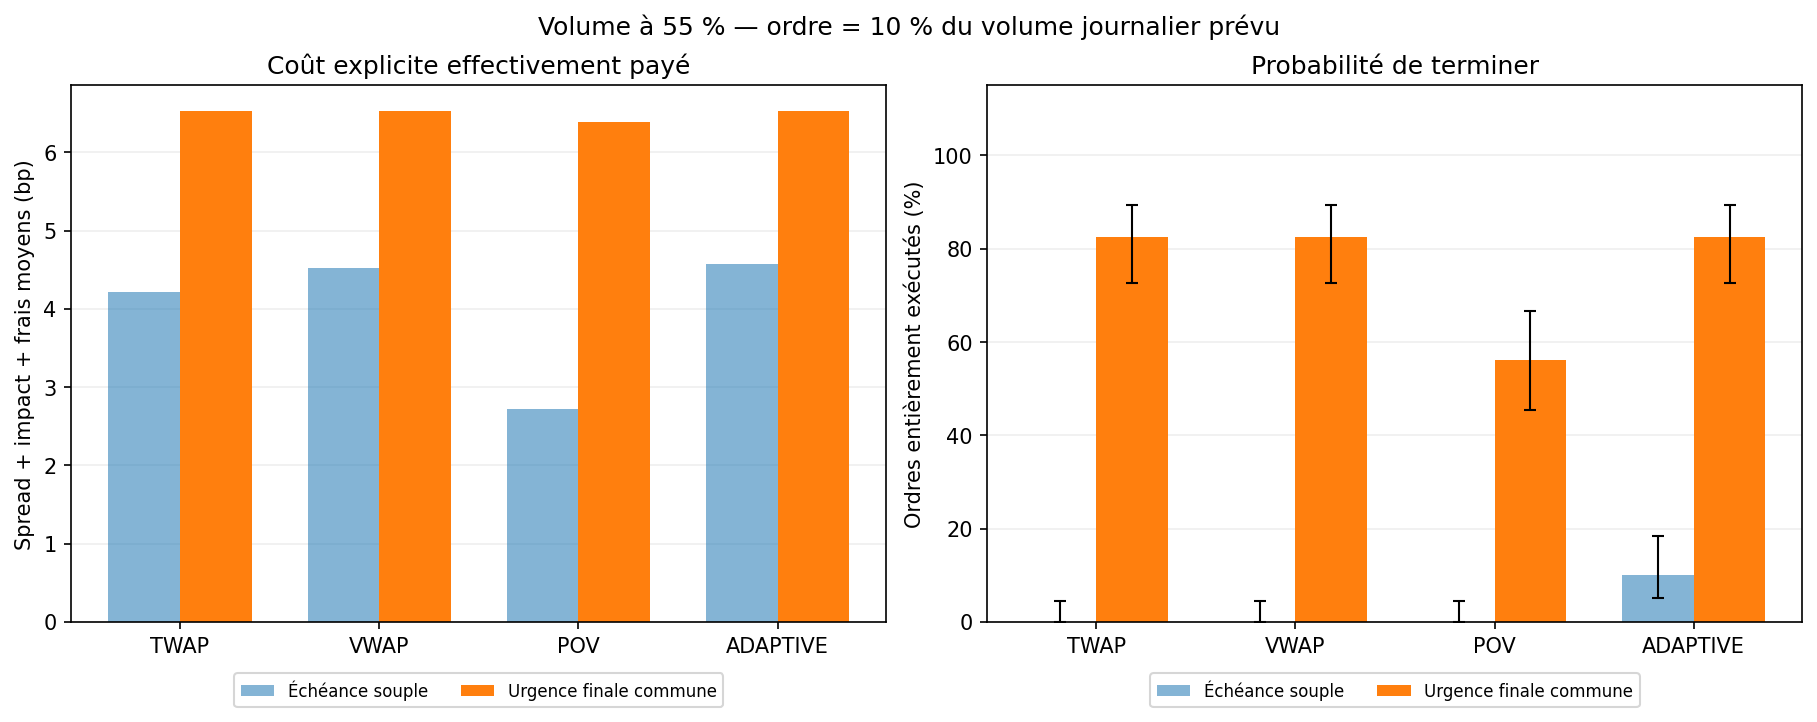

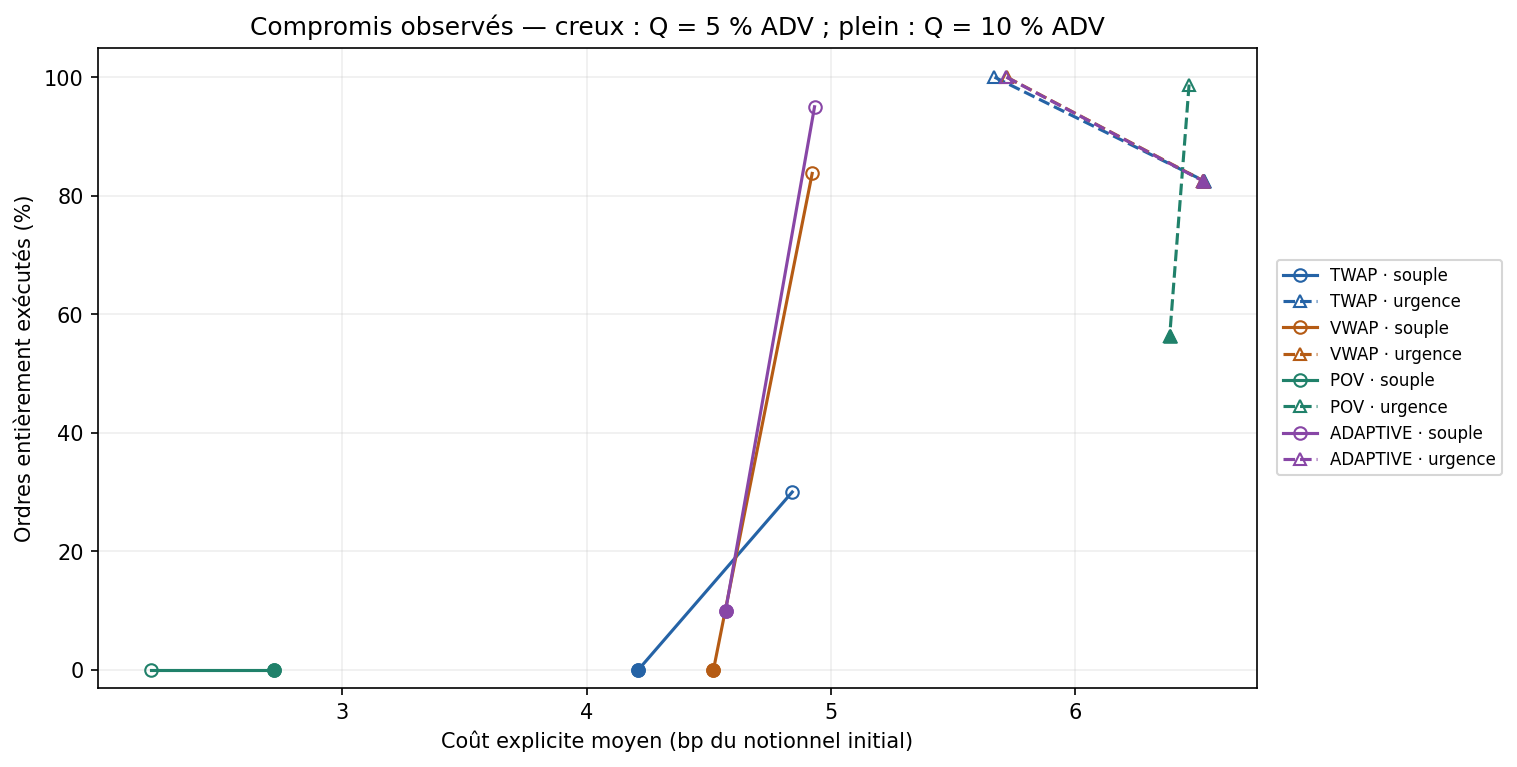

In [3]:
focus = aggregate.loc[
    aggregate["scenario"].eq("low_volume")
    & aggregate["impact_model"].eq("sqrt")
    & np.isclose(aggregate["quantity_adv_ratio"], 0.10)
]
display(
    focus[
        [
            "deadline_mode",
            "strategy",
            "mean_explicit_cost_bps",
            "mean_cost_bps",
            "mean_fill_rate",
            "completion_probability",
            "completion_probability_ci_low",
            "completion_probability_ci_high",
        ]
    ].round(4)
)
display(Image(filename=str(ROOT / "reports/study/figures/completion_cost.png")))
display(Image(filename=str(ROOT / "reports/study/figures/cost_completion_tradeoff.png")))

## 3. Contrôle de subdivision

Même horizon, même prix, même ordre, même participation : la quantité et le volume sont subdivisés proportionnellement. Les modèles linéaire et racine sont normalisés au même impact à 10 % de participation, sans calibration empirique.


In [4]:
grid = grid_invariance_check(protocol)
display(grid)
assert grid["passed"].all()
print("Erreur maximale de réconciliation :", summary["reconciliation_error"].abs().max())
assert summary["reconciliation_error"].abs().max() < 1e-5

,impact_model,n_buckets,total_quantity,total_market_volume,total_cost_bps,impact_cost_bps,max_participation,passed
0,sqrt,26,10400,104000,4.662486,3.162278,0.1,True
1,sqrt,52,10400,104000,4.662486,3.162278,0.1,True
2,sqrt,104,10400,104000,4.662486,3.162278,0.1,True
3,linear,26,10400,104000,4.662486,3.162278,0.1,True
4,linear,52,10400,104000,4.662486,3.162278,0.1,True
5,linear,104,10400,104000,4.662486,3.162278,0.1,True


Erreur maximale de réconciliation : 4.42378222942e-09


## 4. Confrontation aux observations publiques

BTCUSDT et ETHUSDT, janvier 2026, archives Binance Vision vérifiées par SHA-256 et complétude minute par minute. Par actif : 14 jours initiaux et 17 jours évalués chronologiquement. Les marchés ne sont pas regroupés en 34 observations indépendantes.

La référence d'exécution est le VWAP des transactions de la barre, pas un midpoint bid/ask. Décision et arrivée utilisent la première ouverture ; le reliquat la dernière clôture. Spread 2 bp, volatilité 2 % et impact restent hypothétiques. Les intervalles par jour supposent une indépendance temporelle non vérifiée et restent descriptifs.

**Attribution : Binance Vision.** Les résultats historiques de ce notebook sont sous CC BY-NC-SA 4.0 et conditions Binance Vision. Voir `reports/real/LICENSE.md` et `docs/SOURCES.md`.


,scenario,n_pairs,saving_bps,saving_ci_low,saving_ci_high,completion_delta_pp,evidence
15,BTCUSDT,17,-4.9502,-10.1376,-0.6485,0.0,uncertain_or_no_economic_saving
47,ETHUSDT,17,-10.6490,-21.1629,-1.3251,0.0,uncertain_or_no_economic_saving


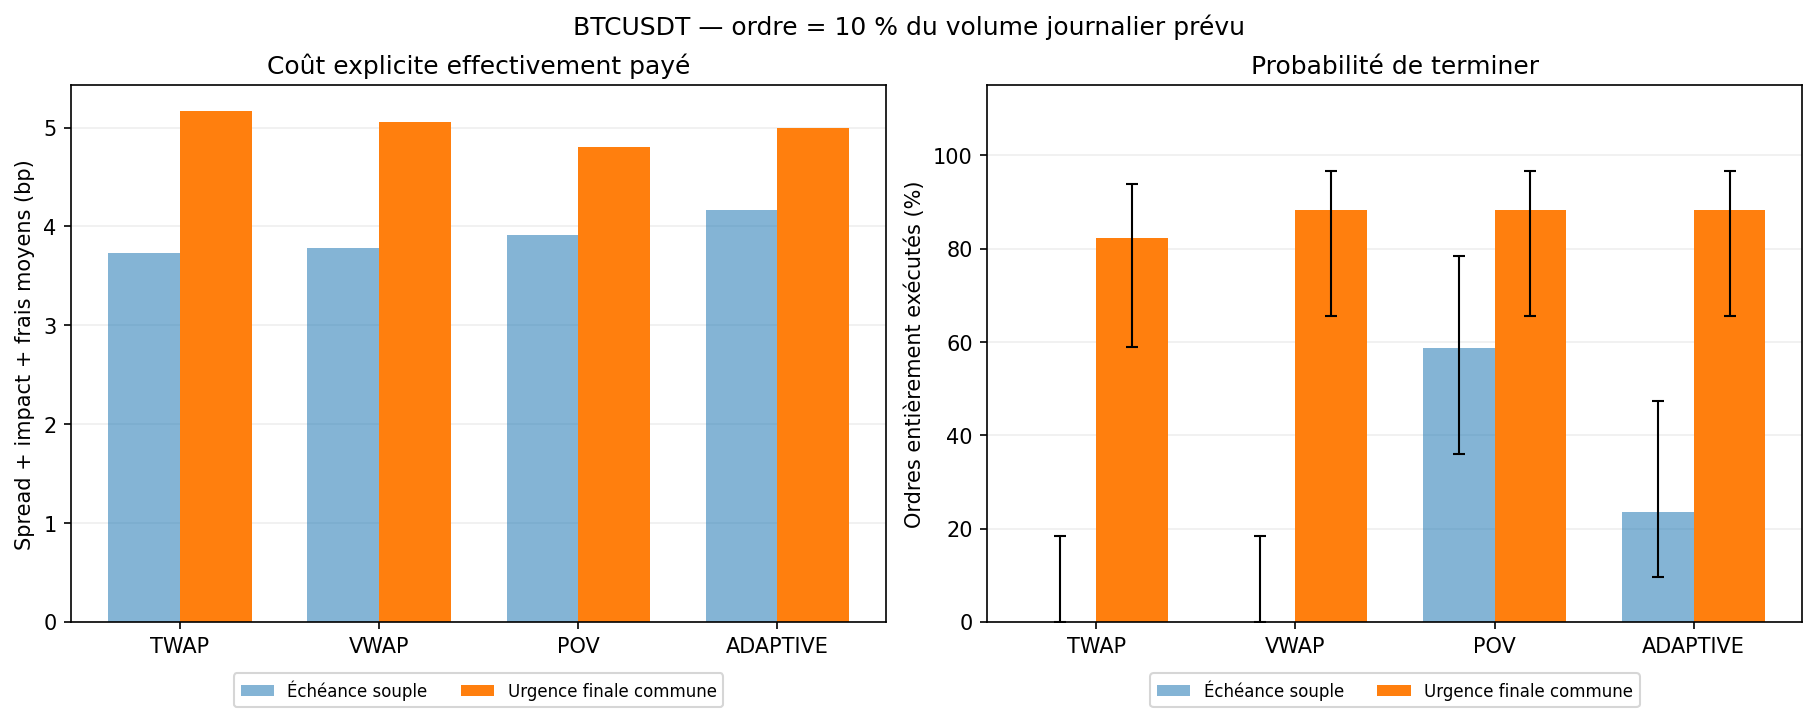

In [5]:
real = pd.read_csv(ROOT / "reports/real/comparisons.csv")
real_focus = real.loc[
    real["strategy"].eq("ADAPTIVE")
    & real["baseline"].eq("VWAP")
    & real["impact_model"].eq("sqrt")
    & real["deadline_mode"].eq("common_deadline")
    & np.isclose(real["quantity_adv_ratio"], 0.10)
]
display(
    real_focus[
        [
            "scenario",
            "n_pairs",
            "saving_bps",
            "saving_ci_low",
            "saving_ci_high",
            "completion_delta_pp",
            "evidence",
        ]
    ].round(4)
)
assert not real["is_primary"].any()
display(Image(filename=str(ROOT / "reports/real/figures/completion_cost.png")))

## 5. Conclusion à défendre

Lire le contraste principal, puis les sensibilités et contre-exemples. Aucun avantage économique n'est établi par le contraste principal de référence. Une autre cellule favorable ne le remplace pas. Une meilleure complétion contre un coût plus élevé reste un compromis à chiffrer.

Les conclusions détaillées sont dans `reports/study/RESULTATS.md` et `reports/real/RESULTATS.md`. Le guide explique comment reproduire, interpréter et modifier l'étude. Les contrôles logiciels établissent la cohérence des calculs ; l'effet causal d'un ordre réel demanderait d'autres données et validations.
